# PRDM9 × G4-seq support-normalized sequential enrichment — production figure v2

This notebook is the production-oriented rewrite of the PRDM9 × predicted/G4-seq-supported G4 enrichment analysis.

The first fixed version showed the key biology in panels A–C, but the adjusted exact-sequence volcano panels still answered an outlier-discovery question. Because unsupported G4s dominate the exact-sequence search space, those panels were again dominated by unsupported sequence identities and therefore conflicted with the support-normalized biological interpretation.

This v2 notebook keeps the correct biological core and removes exact-sequence outlier maps from the main figure. The main figure now asks one coherent question throughout:

> After correcting for the much larger unsupported prediction-only search space, are PRDM9-overlapping G4 hits more enriched for experimentally supported G4s?

Main safeguards:

1. **Fix canonical-to-scored locus matching**: canonical sequences are compared to scored locus sequences, not to the numeric pqsfinder score column.
2. **Use all locus-level G4 overlaps** for the main tests, not PRDM9-selected exact-sequence panels.
3. **Normalize by background opportunity** separately for supported and unsupported G4s.
4. **Test support enrichment conditionally among G4 hits**, stratified by class, pqsfinder score, length, and background prevalence.
5. **Show a sequential adjustment ladder** from raw hits to the fully controlled support-odds model.
6. **Preserve the visual identity**: red = matched background, blue = global background.

Outputs are written under `data_prdm9_g4seq_support_normalized_publication_v2/`.


In [1]:
!pip install scipy pyranges pysam

In [2]:

from __future__ import annotations

import os
import gc
import json
import math
import hashlib
import logging
from pathlib import Path
from collections import Counter
from logging.handlers import RotatingFileHandler
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import norm
from tqdm.auto import tqdm
import pyranges as pr
import pysam
from IPython.display import display

try:
    from rich.console import Console
    from rich.panel import Panel
    from rich.table import Table
    from rich.logging import RichHandler
    RICH_AVAILABLE = True
except Exception:
    RICH_AVAILABLE = False

# ---------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------
RANDOM_SEED = 31
N_WORKERS = min(32, os.cpu_count() or 1)
N_BOOTSTRAP = 5000          # production CIs for support-normalized rates
BOOTSTRAP_CHUNK = 25        # lower if memory is tight
SLACK_BP = 3
CANONICAL = {f"chr{i}" for i in range(1, 23)} | {"chrX", "chrY"}

# production statistical settings
PSEUDOCOUNT = 0.5
MIN_STRATUM_TOTAL_HITS = 20

SAMPLING_DIR = Path("data_prdm9_sampling_production")
OUT_DIR = Path("data_prdm9_g4seq_support_normalized_publication_v2")
TABLE_DIR = OUT_DIR / "tables"
FEATURE_DIR = OUT_DIR / "features"
FIG_DIR = OUT_DIR / "figures"
META_DIR = OUT_DIR / "metadata"
LOG_DIR = OUT_DIR / "logs"
for p in [OUT_DIR, TABLE_DIR, FEATURE_DIR, FIG_DIR, META_DIR, LOG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

PRDM9_BED = SAMPLING_DIR / "prdm9_filtered.bed"
DATASETA_BED = SAMPLING_DIR / "datasetA_matched.len_gc_entropy.bed"
DATASETB_BED = SAMPLING_DIR / "datasetB_global.length_only.bed"

# optional sidecars
PRDM9_STATS = SAMPLING_DIR / "tables" / "prdm9_filtered.stats.tsv"
DATASETA_STATS = SAMPLING_DIR / "tables" / "datasetA_matched.len_gc_entropy.stats.tsv"
DATASETB_STATS = SAMPLING_DIR / "tables" / "datasetB_global.length_only.stats.tsv"

G4_SCORE_BED = Path("g4/pqsfinder_hg38.bed")
G4_SHORT_TXT = Path("g4/G4s_short_pqsfinder_hg38.txt")
G4_MEDIAN_TXT = Path("g4/G4s_median_pqsfinder_hg38.txt")
G4_LONG_TXT = Path("g4/G4s_long_pqsfinder_hg38.txt")
G4_EXPERIMENTAL_BED = Path("g4/HEK293_G4s_hg38.bed")
FASTA = Path("hg38.fa")

WINDOW_MANIFEST_TSV = TABLE_DIR / "window_manifest.tsv"
G4_LOCI_TSV = TABLE_DIR / "g4_loci_support_annotated.tsv"
SEQ_CATALOG_TSV = TABLE_DIR / "g4_exact_sequence_catalog.tsv"
OVERLAPS_PARQUET = FEATURE_DIR / "window_g4_locus_overlaps.parquet"
WINDOW_COUNTS_TSV = TABLE_DIR / "window_support_hit_counts.tsv"
SUPPORT_RATE_TSV = TABLE_DIR / "support_normalized_rate_enrichment.tsv"
SUPPORT_CONTRAST_TSV = TABLE_DIR / "support_enrichment_contrasts.tsv"
STRATUM_TSV = TABLE_DIR / "support_stratified_odds_by_stratum.tsv"
SUPPORT_ODDS_LADDER_TSV = TABLE_DIR / "support_odds_sequential_adjustment_ladder.tsv"
FIG_MAIN_PNG = FIG_DIR / "Figure_PRDM9_G4seq_support_normalized_enrichment.png"
FIG_MAIN_PDF = FIG_DIR / "Figure_PRDM9_G4seq_support_normalized_enrichment.pdf"
FIG_MAIN_SVG = FIG_DIR / "Figure_PRDM9_G4seq_support_normalized_enrichment.svg"
METADATA_JSON = META_DIR / "run_metadata.json"

MATCHED_COLOR = "#B13A3A"   # red
GLOBAL_COLOR = "#2D6FA3"    # blue
DARK = "#222222"
MID = "#777777"
LIGHT = "#D6D6D6"
SUPPORTED_COLOR = "#303030"
UNSUPPORTED_COLOR = "#C8C8C8"
MIXED_COLOR = "#8E8E8E"

# Nature-ish compact plotting defaults
mpl.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 450,
    "font.size": 8.5,
    "axes.titlesize": 9.5,
    "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.title_fontsize": 8.0,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

if RICH_AVAILABLE:
    console = Console()
else:
    console = None

logger = logging.getLogger("prdm9_g4seq_support_normalized")
logger.setLevel(logging.INFO)
logger.handlers = []
if RICH_AVAILABLE:
    logger.addHandler(RichHandler(console=console, rich_tracebacks=True, markup=True))
else:
    stream_handler = logging.StreamHandler()
    stream_handler.setFormatter(logging.Formatter("%(levelname)s | %(message)s"))
    logger.addHandler(stream_handler)
file_handler = RotatingFileHandler(LOG_DIR / "run.log", maxBytes=5_000_000, backupCount=3)
file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(file_handler)

if RICH_AVAILABLE:
    console.print(Panel.fit(
        f"[bold]PRDM9 × G4-seq support-normalized enrichment[/bold]\n"
        f"Workers: {N_WORKERS}\n"
        f"Bootstrap replicates: {N_BOOTSTRAP:,}\n"
        f"Main figure: {FIG_MAIN_PDF}\n"
        f"Main figure logic: support-normalized rates + conditional support odds",
        title="Run configuration"
    ))
else:
    logger.info(f"Workers={N_WORKERS}; bootstrap={N_BOOTSTRAP}; output={OUT_DIR}")



INFO | Workers=32; bootstrap=5000; output=data_prdm9_g4seq_support_normalized_publication_v2


## Helper functions

These utilities implement the core statistical safeguards:

- **FDR correction** with Benjamini–Hochberg.
- **Background-only exact-sequence selection**.
- **Window bootstrap** for support-normalized rate ratios.
- **Stratified inverse-variance support odds ratio** across `class × score quartile × length quartile × background-prevalence quartile` strata.
- **Weighted residualization and empirical-Bayes shrinkage** for the exact-sequence volcano panels.

In [3]:

def read_bed3(path: Path, set_name: str | None = None) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(path)
    df = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    if set_name is not None:
        df["WindowSet"] = set_name
    return df


def read_optional_sidecar(path: Path) -> pd.DataFrame | None:
    if not path.exists():
        return None
    df = pd.read_csv(path, sep="\t")
    need = {"Chromosome", "Start", "End"}
    if not need.issubset(df.columns):
        return None
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    return df


def attach_optional_metadata(df: pd.DataFrame, sidecar: pd.DataFrame | None) -> pd.DataFrame:
    if sidecar is None:
        return df
    meta_cols = [c for c in sidecar.columns if c not in df.columns and c not in {"Chromosome", "Start", "End"}]
    if not meta_cols:
        return df
    return df.merge(sidecar[["Chromosome", "Start", "End"] + meta_cols], on=["Chromosome", "Start", "End"], how="left")


def add_window_keys(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["window_len"] = (out["End"] - out["Start"]).astype(np.int64)
    out["window_key"] = (
        out["WindowSet"].astype(str) + "::" + out["Chromosome"].astype(str) + ":" +
        out["Start"].astype(str) + "-" + out["End"].astype(str)
    )
    return out


def assert_valid_intervals(df: pd.DataFrame, name: str) -> None:
    if df.empty:
        raise ValueError(f"{name} is empty")
    bad = int((df["End"] <= df["Start"]).sum())
    if bad:
        raise ValueError(f"{name} contains {bad:,} intervals with End <= Start")


def read_pqsfinder_bed(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(path)
    df = pd.read_csv(
        path,
        sep="\t",
        header=None,
        usecols=[0, 1, 2, 3, 4, 5],
        names=["Chromosome", "Start", "End", "Name", "Score", "Strand"],
    )
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    df["Score"] = pd.to_numeric(df["Score"], errors="coerce").fillna(0.0).astype(np.float64)
    df["Strand"] = df["Strand"].astype(str)
    return df


def read_canonical_txt(path: Path, size_class: str) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(path)
    df = pd.read_csv(path, sep="\t", header=0)
    rename = {}
    if "seqnames" in df.columns:
        rename["seqnames"] = "Chromosome"
    if "start" in df.columns:
        rename["start"] = "Start"
    if "end" in df.columns:
        rename["end"] = "End"
    df = df.rename(columns=rename)
    keep = ["Chromosome", "Start", "End"]
    if "sequence" in df.columns:
        keep.append("sequence")
    df = df[keep].copy()
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    if "sequence" in df.columns:
        df["sequence"] = df["sequence"].astype(str).str.upper()
    else:
        df["sequence"] = np.nan
    df["SizeClass"] = size_class
    return df


def stable_seq_hash(seq: str, n: int = 16) -> str:
    return hashlib.sha1(str(seq).encode("utf-8")).hexdigest()[:n]


def bh_fdr(p: np.ndarray) -> np.ndarray:
    p = np.asarray(p, dtype=np.float64)
    n = len(p)
    if n == 0:
        return p
    order = np.argsort(p)
    ranked = p[order]
    q = ranked * n / (np.arange(n) + 1.0)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n, dtype=np.float64)
    out[order] = np.clip(q, 0, 1)
    return out


def rank_bins(values: pd.Series | np.ndarray, n_bins: int = 4, prefix: str = "Q") -> np.ndarray:
    v = np.asarray(values, dtype=np.float64)
    if len(v) == 0:
        return np.array([], dtype=object)
    order = np.argsort(v, kind="mergesort")
    ranks = np.empty(len(v), dtype=np.int64)
    ranks[order] = np.arange(len(v), dtype=np.int64)
    b = np.floor(ranks / max(len(v), 1) * n_bins).astype(np.int64) + 1
    b = np.clip(b, 1, n_bins)
    return np.array([f"{prefix}{i}" for i in b], dtype=object)


def pretty_class_label(x: str) -> str:
    return {"short": "Short", "medium": "Medium", "long": "Long", "noncanon": "Noncanon"}.get(str(x).lower(), str(x).title())


def support_display_label(frac_supported: float) -> str:
    if frac_supported >= 0.75:
        return "Supported"
    if frac_supported <= 0.25:
        return "Unsupported"
    return "Mixed"


def save_table(df: pd.DataFrame, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, sep="\t", index=False)


def save_parquet(df: pd.DataFrame, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    try:
        df.to_parquet(path, index=False)
        return path
    except Exception as e:
        fallback = path.with_suffix(".pkl")
        logger.warning(f"Could not write parquet ({e}); writing pickle fallback: {fallback}")
        df.to_pickle(fallback)
        return fallback


def load_parquet_or_pickle(path: Path) -> pd.DataFrame:
    if path.exists():
        return pd.read_parquet(path)
    fallback = path.with_suffix(".pkl")
    if fallback.exists():
        return pd.read_pickle(fallback)
    raise FileNotFoundError(path)


def reciprocal_overlap(a_start, a_end, b_start, b_end):
    inter = np.maximum(0, np.minimum(a_end, b_end) - np.maximum(a_start, b_start))
    len_a = np.maximum(1, a_end - a_start)
    len_b = np.maximum(1, b_end - b_start)
    return inter / len_a, inter / len_b, inter


def bootstrap_support_rates(pos: pd.DataFrame, bg: pd.DataFrame, n_boot: int, seed: int) -> pd.DataFrame:
    """Window bootstrap preserving support/unsupported correlation within windows."""
    rng = np.random.default_rng(seed)
    pos_sup = pos["supported_hits"].to_numpy(np.float64)
    pos_uns = pos["unsupported_hits"].to_numpy(np.float64)
    bg_sup = bg["supported_hits"].to_numpy(np.float64)
    bg_uns = bg["unsupported_hits"].to_numpy(np.float64)
    n_pos = len(pos_sup)
    n_bg = len(bg_sup)

    out = {
        "supported_log2rr": [],
        "unsupported_log2rr": [],
        "did_log2rr": [],
    }
    done = 0
    while done < n_boot:
        m = min(BOOTSTRAP_CHUNK, n_boot - done)
        ip = rng.integers(0, n_pos, size=(m, n_pos), endpoint=False)
        ib = rng.integers(0, n_bg, size=(m, n_bg), endpoint=False)
        ps = pos_sup[ip].sum(axis=1)
        pu = pos_uns[ip].sum(axis=1)
        bs = bg_sup[ib].sum(axis=1)
        bu = bg_uns[ib].sum(axis=1)
        sup = np.log2(((ps + PSEUDOCOUNT) / n_pos) / ((bs + PSEUDOCOUNT) / n_bg))
        uns = np.log2(((pu + PSEUDOCOUNT) / n_pos) / ((bu + PSEUDOCOUNT) / n_bg))
        out["supported_log2rr"].extend(sup.tolist())
        out["unsupported_log2rr"].extend(uns.tolist())
        out["did_log2rr"].extend((sup - uns).tolist())
        done += m
    return pd.DataFrame(out)


def effect_ci(x: np.ndarray, lo: float = 2.5, hi: float = 97.5) -> tuple[float, float]:
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan, np.nan
    return float(np.percentile(x, lo)), float(np.percentile(x, hi))


def two_sided_bootstrap_p(x: np.ndarray, null: float = 0.0) -> float:
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return 1.0
    p_left = np.mean(x <= null)
    p_right = np.mean(x >= null)
    return float(min(1.0, 2.0 * min(p_left, p_right) + 1.0 / (len(x) + 1.0)))


def add_panel_label(ax, label: str, x: float = -0.13, y: float = 1.08) -> None:
    ax.text(x, y, label, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top", ha="left")


def despine(ax) -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

## 1. Load PRDM9 and background windows

The matched background (`datasetA_matched`) is kept as the **red** comparison. The global background (`datasetB_global`) is kept as the **blue** comparison.

In [4]:

logger.info("[1/8] Loading PRDM9 and background windows")

prdm9 = add_window_keys(read_bed3(PRDM9_BED, "prdm9"))
datasetA = add_window_keys(read_bed3(DATASETA_BED, "datasetA_matched"))
datasetB = add_window_keys(read_bed3(DATASETB_BED, "datasetB_global"))

prdm9 = attach_optional_metadata(prdm9, read_optional_sidecar(PRDM9_STATS))
datasetA = attach_optional_metadata(datasetA, read_optional_sidecar(DATASETA_STATS))
datasetB = attach_optional_metadata(datasetB, read_optional_sidecar(DATASETB_STATS))

windows = pd.concat([prdm9, datasetA, datasetB], ignore_index=True)
windows = windows[windows["Chromosome"].isin(CANONICAL)].copy().reset_index(drop=True)
windows["window_id"] = np.arange(len(windows), dtype=np.int64)

if windows["window_key"].duplicated().any():
    raise AssertionError(f"Window keys are not unique: {int(windows['window_key'].duplicated().sum()):,} duplicates found")
assert_valid_intervals(windows, "windows")

meta_cols_present = [c for c in windows.columns if c.lower() in {"assembly", "assembly_name", "sample_id", "haplotype"}]
window_cols = ["window_id", "window_key", "WindowSet", "Chromosome", "Start", "End", "window_len"] + meta_cols_present
save_table(windows[window_cols], WINDOW_MANIFEST_TSV)

summary = windows.groupby("WindowSet", sort=False).size().reset_index(name="n_windows")
display(summary)
logger.info(f"Windows loaded: {len(windows):,}; manifest written to {WINDOW_MANIFEST_TSV}")

INFO | [1/8] Loading PRDM9 and background windows


,WindowSet,n_windows
0,prdm9,60580
1,datasetA_matched,181740
2,datasetB_global,181740


INFO | Windows loaded: 424,060; manifest written to data_prdm9_g4seq_support_normalized_publication_v2/tables/window_manifest.tsv


## 2. Load G4 loci and annotate canonical class + G4-seq support

This section intentionally fixes a likely typo from the reproduced notebook. Canonical interval sequences are compared to the **scored locus sequence**, not to the numeric pqsfinder score.

In [5]:

logger.info("[2/8] Loading pqsfinder loci, extracting exact sequences, and annotating support")

g4 = read_pqsfinder_bed(G4_SCORE_BED)
g4 = g4[g4["Chromosome"].isin(CANONICAL)].copy().reset_index(drop=True)
assert_valid_intervals(g4, "pqsfinder BED")
g4["g4_id"] = np.arange(len(g4), dtype=np.int64)

if not FASTA.exists():
    raise FileNotFoundError(FASTA)
fa = pysam.FastaFile(str(FASTA))
seqs = []
for row in tqdm(g4.itertuples(index=False), total=len(g4), desc="extracting pqsfinder sequences"):
    seqs.append(fa.fetch(row.Chromosome, int(row.Start), int(row.End)).upper())
fa.close()
g4["sequence"] = seqs
g4["sequence_hash"] = [stable_seq_hash(s) for s in g4["sequence"]]
g4["length_nt"] = g4["sequence"].str.len().astype(np.int64)

g4["Q_label"] = rank_bins(g4["Score"], 4, "Q")
g4["length_bin"] = rank_bins(g4["length_nt"], 4, "L")

# canonical class matching with small coordinate slack and sequence identity priority
canonical = pd.concat([
    read_canonical_txt(G4_SHORT_TXT, "short"),
    read_canonical_txt(G4_MEDIAN_TXT, "medium"),
    read_canonical_txt(G4_LONG_TXT, "long"),
], ignore_index=True)
canonical = canonical[canonical["Chromosome"].isin(CANONICAL)].copy().reset_index(drop=True)
assert_valid_intervals(canonical, "canonical G4 intervals")
canonical["seq_id"] = np.arange(len(canonical), dtype=np.int64)

score_join = g4[["Chromosome", "Start", "End", "g4_id", "Score", "length_nt", "sequence"]].copy()
score_join = score_join.rename(columns={"sequence": "score_sequence"})
score_join["score_len"] = (score_join["End"] - score_join["Start"]).astype(np.int64)

canon_join = canonical[["Chromosome", "Start", "End", "seq_id", "SizeClass", "sequence"]].copy()
canon_join = canon_join.rename(columns={"Start": "orig_Start", "End": "orig_End", "sequence": "canon_sequence"})
canon_join["Start"] = (canon_join["orig_Start"] - SLACK_BP).clip(lower=0).astype(np.int64)
canon_join["End"] = (canon_join["orig_End"] + SLACK_BP).astype(np.int64)

candidates = pr.PyRanges(canon_join).join(
    pr.PyRanges(score_join[["Chromosome", "Start", "End", "g4_id", "Score", "score_len", "score_sequence"]]),
    suffix="_score"
).df

if candidates.empty:
    raise RuntimeError("No canonical-to-score candidate pairs found")

candidates["abs_start_diff"] = (candidates["orig_Start"] - candidates["Start_score"]).abs().astype(np.int64)
candidates["abs_end_diff"] = (candidates["orig_End"] - candidates["End_score"]).abs().astype(np.int64)
candidates["sum_delta"] = (candidates["abs_start_diff"] + candidates["abs_end_diff"]).astype(np.int64)
candidates["len_delta"] = ((candidates["orig_End"] - candidates["orig_Start"]) - (candidates["End_score"] - candidates["Start_score"])).abs().astype(np.int64)
_, _, ov = reciprocal_overlap(
    candidates["orig_Start"].to_numpy(np.int64),
    candidates["orig_End"].to_numpy(np.int64),
    candidates["Start_score"].to_numpy(np.int64),
    candidates["End_score"].to_numpy(np.int64),
)
candidates["overlap_bp"] = ov.astype(np.int64)
candidates["seq_exact_match"] = (
    candidates["canon_sequence"].fillna("").astype(str).str.upper() ==
    candidates["score_sequence"].fillna("").astype(str).str.upper()
)

candidates = candidates[
    (candidates["abs_start_diff"] <= SLACK_BP) &
    (candidates["abs_end_diff"] <= SLACK_BP) &
    (candidates["overlap_bp"] > 0)
].copy()

candidates = candidates.sort_values(
    ["seq_exact_match", "sum_delta", "len_delta", "abs_start_diff", "abs_end_diff", "overlap_bp", "g4_id", "seq_id"],
    ascending=[False, True, True, True, True, False, True, True],
).reset_index(drop=True)

used_seq = set()
used_g4 = set()
chosen_rows = []
for row in tqdm(candidates.itertuples(index=False), total=len(candidates), desc="matching canonical→score"):
    if row.seq_id in used_seq or row.g4_id in used_g4:
        continue
    chosen_rows.append(row)
    used_seq.add(row.seq_id)
    used_g4.add(row.g4_id)
match_df = pd.DataFrame(chosen_rows)

g4["SizeClass"] = "noncanon"
if not match_df.empty:
    g4 = g4.merge(match_df[["g4_id", "SizeClass"]].drop_duplicates(), on="g4_id", how="left", suffixes=("", "_matched"))
    g4["SizeClass"] = g4["SizeClass_matched"].fillna(g4["SizeClass"])
    g4 = g4.drop(columns=["SizeClass_matched"])

# G4-seq support: any overlap with merged experimental peaks
experimental = read_bed3(G4_EXPERIMENTAL_BED)
experimental = experimental[experimental["Chromosome"].isin(CANONICAL)].copy()
assert_valid_intervals(experimental, "experimental G4-seq BED")
experimental_merged = pr.PyRanges(experimental).merge().df
support_hits = pr.PyRanges(g4[["Chromosome", "Start", "End", "g4_id"]]).join(
    pr.PyRanges(experimental_merged[["Chromosome", "Start", "End"]]),
    suffix="_exp"
).df
supported_ids = set([] if support_hits.empty else support_hits["g4_id"].unique())
g4["Supported"] = g4["g4_id"].isin(supported_ids)
g4["support_state"] = np.where(g4["Supported"], "Supported", "Unsupported")
g4["class_display"] = g4["SizeClass"].map(pretty_class_label)

loci_cols = [
    "g4_id", "Chromosome", "Start", "End", "Strand", "Score", "Q_label", "length_nt", "length_bin",
    "sequence", "sequence_hash", "SizeClass", "class_display", "Supported", "support_state"
]
save_table(g4[loci_cols], G4_LOCI_TSV)

logger.info(
    f"G4 loci annotated: total={len(g4):,}; supported={int(g4['Supported'].sum()):,}; "
    f"unsupported={int((~g4['Supported']).sum()):,}; canonical={int((g4['SizeClass'] != 'noncanon').sum()):,}"
)

composition_loci = g4["support_state"].value_counts().rename_axis("support_group").reset_index(name="n_loci")
display(composition_loci)

INFO | [2/8] Loading pqsfinder loci, extracting exact sequences, and annotating support


extracting pqsfinder sequences:   0%|          | 0/1352359 [00:00<?, ?it/s]

matching canonical→score:   0%|          | 0/1835925 [00:00<?, ?it/s]

INFO | G4 loci annotated: total=1,352,359; supported=194,942; unsupported=1,157,417; canonical=1,058,284


,support_group,n_loci
0,Unsupported,1157417
1,Supported,194942


## 3. Build exact-sequence catalog

The exact-sequence catalog is still useful, but it is used carefully: the main biological test is not driven by the number of exact unsupported sequences.

In [6]:

logger.info("[3/8] Building exact-sequence catalog")

priority_class = ["long", "medium", "short", "noncanon"]
priority_q = ["Q4", "Q3", "Q2", "Q1"]

def dominant_with_priority(values, priority):
    counts = Counter(values)
    if not counts:
        return None, 0.0
    best = sorted(counts.items(), key=lambda kv: (-kv[1], priority.index(kv[0]) if kv[0] in priority else 999, str(kv[0])))[0][0]
    return best, float(counts[best] / sum(counts.values()))

seq_rows = []
for seq, sub in tqdm(g4.groupby("sequence", sort=False), desc="sequence catalog"):
    class_mode, class_purity = dominant_with_priority(sub["SizeClass"].tolist(), priority_class)
    q_mode, q_purity = dominant_with_priority(sub["Q_label"].tolist(), priority_q)
    support_frac = float(sub["Supported"].mean())
    seq_rows.append({
        "sequence": seq,
        "sequence_hash": stable_seq_hash(seq),
        "length_nt": int(len(seq)),
        "n_loci": int(len(sub)),
        "n_chromosomes": int(sub["Chromosome"].nunique()),
        "score_median": float(sub["Score"].median()),
        "score_mean": float(sub["Score"].mean()),
        "score_sd": float(sub["Score"].std(ddof=0)) if len(sub) > 1 else 0.0,
        "class_mode": class_mode,
        "class_display": pretty_class_label(class_mode),
        "class_purity": class_purity,
        "q_mode": q_mode,
        "q_purity": q_purity,
        "support_frac": support_frac,
        "support_display": support_display_label(support_frac),
        "n_supported_loci": int(sub["Supported"].sum()),
        "n_unsupported_loci": int((~sub["Supported"]).sum()),
    })

seq_catalog = pd.DataFrame(seq_rows).sort_values(
    ["n_loci", "length_nt", "score_median", "sequence_hash"],
    ascending=[False, False, False, True]
).reset_index(drop=True)

if seq_catalog["sequence_hash"].duplicated().any():
    n_dup = int(seq_catalog["sequence_hash"].duplicated().sum())
    logger.warning(f"Sequence-hash collisions detected: {n_dup:,}. Consider increasing hash length.")

save_table(seq_catalog, SEQ_CATALOG_TSV)
composition_sequences = seq_catalog["support_display"].value_counts().rename_axis("support_group").reset_index(name="n_sequences")
logger.info(f"Exact sequence catalog written: {SEQ_CATALOG_TSV}")
display(composition_sequences)

INFO | [3/8] Building exact-sequence catalog


sequence catalog:   0%|          | 0/1172688 [00:00<?, ?it/s]

IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
IOStream.flush timed out
INFO | Exact sequence catalog written: data_prdm9_g4seq_support_normalized_publication_v2/tables/g4_exact_sequence_catalog.tsv


,support_group,n_sequences
0,Unsupported,982950
1,Supported,186252
2,Mixed,3486


## 4. Intersect windows with G4 loci

The support-normalized statistics use **all locus-level overlaps**. This avoids selecting a PRDM9-enriched exact sequence panel before testing.

In [7]:

logger.info("[4/8] Intersecting windows with G4 loci")

windows_by_chr = {chrom: sub.copy() for chrom, sub in windows.groupby("Chromosome", sort=False)}
g4_by_chr = {chrom: sub.copy() for chrom, sub in g4.groupby("Chromosome", sort=False)}

def process_chromosome_overlaps(chrom: str, win_df: pd.DataFrame, g4_df: pd.DataFrame) -> pd.DataFrame:
    if win_df.empty or g4_df.empty:
        return pd.DataFrame(columns=["window_id", "g4_id", "overlap_bp"])
    win_pr = pr.PyRanges(win_df[["Chromosome", "Start", "End", "window_id"]])
    g4_pr = pr.PyRanges(g4_df[["Chromosome", "Start", "End", "g4_id"]])
    joined = win_pr.join(g4_pr, suffix="_g4").df
    if joined.empty:
        return pd.DataFrame(columns=["window_id", "g4_id", "overlap_bp"])
    joined["overlap_bp"] = (
        np.minimum(joined["End"].to_numpy(np.int64), joined["End_g4"].to_numpy(np.int64)) -
        np.maximum(joined["Start"].to_numpy(np.int64), joined["Start_g4"].to_numpy(np.int64))
    ).astype(np.int64)
    joined = joined[joined["overlap_bp"] > 0]
    return joined[["window_id", "g4_id", "overlap_bp"]].drop_duplicates().reset_index(drop=True)

chrom_jobs = [
    (chrom, windows_by_chr.get(chrom, pd.DataFrame()), g4_by_chr.get(chrom, pd.DataFrame()))
    for chrom in sorted(CANONICAL)
    if chrom in windows_by_chr and chrom in g4_by_chr
]

def run_overlap_jobs(chrom_jobs):
    parts = []
    if N_WORKERS <= 1 or len(chrom_jobs) <= 1:
        for chrom, win_df, g4_df in tqdm(chrom_jobs, desc="chromosomes"):
            res = process_chromosome_overlaps(chrom, win_df, g4_df)
            logger.info(f"{chrom}: {len(res):,} window×G4 overlaps")
            if len(res):
                parts.append(res)
        return parts
    try:
        with ProcessPoolExecutor(max_workers=min(N_WORKERS, len(chrom_jobs))) as ex:
            futs = {ex.submit(process_chromosome_overlaps, chrom, win_df, g4_df): chrom for chrom, win_df, g4_df in chrom_jobs}
            for fut in tqdm(as_completed(futs), total=len(futs), desc="window×G4 by chromosome"):
                chrom = futs[fut]
                res = fut.result()
                logger.info(f"{chrom}: {len(res):,} window×G4 overlaps")
                if len(res):
                    parts.append(res)
        return parts
    except Exception as e:
        logger.warning(f"Parallel chromosome overlap failed ({e}); retrying sequentially")
        parts = []
        for chrom, win_df, g4_df in tqdm(chrom_jobs, desc="chromosomes sequential fallback"):
            res = process_chromosome_overlaps(chrom, win_df, g4_df)
            if len(res):
                parts.append(res)
        return parts

parts = run_overlap_jobs(chrom_jobs)
if not parts:
    raise RuntimeError("No window×G4 overlaps were found")

overlaps = pd.concat(parts, ignore_index=True)
overlaps = overlaps.merge(windows[window_cols], on="window_id", how="left")
overlaps = overlaps.merge(
    g4[[
        "g4_id", "sequence", "sequence_hash", "Score", "Q_label", "length_nt", "length_bin",
        "SizeClass", "class_display", "Supported", "support_state"
    ]],
    on="g4_id",
    how="left",
)

if overlaps[["window_id", "g4_id"]].duplicated().any():
    raise AssertionError("Duplicate window_id × g4_id rows detected after overlap construction")
if overlaps["support_state"].isna().any():
    raise AssertionError("Missing support annotation after merging overlaps with G4 loci")

save_parquet(overlaps, OVERLAPS_PARQUET)
logger.info(f"Overlaps written: {OVERLAPS_PARQUET}; rows={len(overlaps):,}")
display(overlaps.head())

INFO | [4/8] Intersecting windows with G4 loci


window×G4 by chromosome:   0%|          | 0/24 [00:00<?, ?it/s]

INFO | chr1: 120,022 window×G4 overlaps
INFO | chr10: 51,058 window×G4 overlaps
INFO | chr11: 60,333 window×G4 overlaps
INFO | chr12: 36,148 window×G4 overlaps
INFO | chr13: 16,802 window×G4 overlaps
INFO | chr14: 29,648 window×G4 overlaps
INFO | chr15: 30,746 window×G4 overlaps
INFO | chr16: 55,395 window×G4 overlaps
INFO | chr17: 64,510 window×G4 overlaps
INFO | chr18: 15,468 window×G4 overlaps
INFO | chr19: 80,278 window×G4 overlaps
INFO | chr2: 49,966 window×G4 overlaps
INFO | chr20: 28,802 window×G4 overlaps
INFO | chr21: 16,528 window×G4 overlaps
INFO | chr22: 36,521 window×G4 overlaps
INFO | chr3: 29,578 window×G4 overlaps
INFO | chr4: 26,546 window×G4 overlaps
INFO | chr5: 26,408 window×G4 overlaps
INFO | chr6: 24,111 window×G4 overlaps
INFO | chr7: 40,870 window×G4 overlaps
INFO | chr8: 32,523 window×G4 overlaps
INFO | chr9: 37,240 window×G4 overlaps
INFO | chrY: 8,084 window×G4 overlaps
INFO | chrX: 20,521 window×G4 overlaps
INFO | Overlaps written: data_prdm9_g4seq_support_n

,window_id,g4_id,overlap_bp,window_key,WindowSet,Chromosome,Start,End,window_len,sequence,sequence_hash,Score,Q_label,length_nt,length_bin,SizeClass,class_display,Supported,support_state
0,0,27,38,prdm9::chr1:15638-17806,prdm9,chr1,15638,17806,2168,GGGGAAGCAGGGGCCAGCTGGCAAGAGCAGGGGGTGGG,42bae6a651311e55,69.0,Q3,38,L3,long,Long,False,Unsupported
1,0,28,44,prdm9::chr1:15638-17806,prdm9,chr1,15638,17806,2168,GGGGAACAGGGCAAGGAGGAAAGGCTGCTCAGGCAGGGCTGGGG,d9ee58bd16652507,55.0,Q1,44,L4,short,Short,False,Unsupported
2,0,29,41,prdm9::chr1:15638-17806,prdm9,chr1,15638,17806,2168,GGGGAGGCCGGACCTTTGGAGACTGTGTGTGGGGGCCTGGG,7be2fab99921a777,53.0,Q1,41,L4,long,Long,False,Unsupported
3,0,30,41,prdm9::chr1:15638-17806,prdm9,chr1,15638,17806,2168,CCTGCTTCCTCTCTAGCCCCCACCCTGCAGAGCTGGACCCC,e042eb16cc544f60,57.0,Q1,41,L4,noncanon,Noncanon,False,Unsupported
4,0,31,29,prdm9::chr1:15638-17806,prdm9,chr1,15638,17806,2168,GGGGCCGCGGTTGAGGGTGGGAGTGGGGG,9490c9b45a5cbb71,84.0,Q4,29,L2,short,Short,False,Unsupported


## 5. Window-level support-normalized enrichment

This is the first main biological test.

For each background, the notebook estimates:

\[
\log_2 RR_s = \log_2\left(\frac{\text{G4 hits of support class }s\text{ per PRDM9 window}}{\text{G4 hits of support class }s\text{ per background window}}\right)
\]

Then it estimates a difference-in-differences:

\[
\Delta_\mathrm{support} = \log_2 RR_\mathrm{supported} - \log_2 RR_\mathrm{unsupported}
\]

A positive value means supported G4s are more PRDM9-enriched than unsupported G4s after normalizing by the available background opportunity.

In [8]:

logger.info("[5/8] Support-normalized window-level enrichment")

support_counts = (
    overlaps.groupby(["window_id", "support_state"]).size().unstack(fill_value=0)
)
for col in ["Supported", "Unsupported"]:
    if col not in support_counts.columns:
        support_counts[col] = 0
support_counts = support_counts[["Supported", "Unsupported"]].rename(columns={
    "Supported": "supported_hits",
    "Unsupported": "unsupported_hits",
}).reset_index()

window_counts = windows[window_cols].merge(support_counts, on="window_id", how="left")
window_counts[["supported_hits", "unsupported_hits"]] = window_counts[["supported_hits", "unsupported_hits"]].fillna(0).astype(np.int64)
window_counts["total_g4_hits"] = window_counts["supported_hits"] + window_counts["unsupported_hits"]
save_table(window_counts, WINDOW_COUNTS_TSV)

rate_rows = []
contrast_rows = []
boot_store = {}
for bg_name, color_name in [("datasetA_matched", "matched"), ("datasetB_global", "global")]:
    pos = window_counts[window_counts["WindowSet"] == "prdm9"].copy()
    bg = window_counts[window_counts["WindowSet"] == bg_name].copy()
    if pos.empty or bg.empty:
        raise RuntimeError(f"Empty comparison for {bg_name}")

    boot = bootstrap_support_rates(pos, bg, N_BOOTSTRAP, RANDOM_SEED + (11 if bg_name == "datasetA_matched" else 37))
    boot_store[bg_name] = boot

    for support_label, col, boot_col in [
        ("Supported", "supported_hits", "supported_log2rr"),
        ("Unsupported", "unsupported_hits", "unsupported_log2rr"),
    ]:
        hits_pos = float(pos[col].sum())
        hits_bg = float(bg[col].sum())
        rate_pos = (hits_pos + PSEUDOCOUNT) / len(pos)
        rate_bg = (hits_bg + PSEUDOCOUNT) / len(bg)
        log2rr = float(np.log2(rate_pos / rate_bg))
        se = float(np.sqrt(1.0 / (hits_pos + PSEUDOCOUNT) + 1.0 / (hits_bg + PSEUDOCOUNT)) / np.log(2))
        p = float(2 * norm.sf(abs(log2rr / se))) if se > 0 else 1.0
        ci_lo, ci_hi = effect_ci(boot[boot_col].to_numpy())
        rate_rows.append({
            "background_name": bg_name,
            "background_label": "Matched background" if bg_name == "datasetA_matched" else "Global background",
            "color_group": color_name,
            "support_group": support_label,
            "n_prdm9_windows": len(pos),
            "n_background_windows": len(bg),
            "hits_prdm9": hits_pos,
            "hits_background": hits_bg,
            "rate_prdm9": rate_pos,
            "rate_background": rate_bg,
            "log2_rate_ratio": log2rr,
            "ci_low": ci_lo,
            "ci_high": ci_hi,
            "se_poisson": se,
            "p_poisson": p,
            "p_bootstrap": two_sided_bootstrap_p(boot[boot_col].to_numpy(), 0.0),
        })

    did = (
        np.log2(((pos["supported_hits"].sum() + PSEUDOCOUNT) / len(pos)) / ((bg["supported_hits"].sum() + PSEUDOCOUNT) / len(bg))) -
        np.log2(((pos["unsupported_hits"].sum() + PSEUDOCOUNT) / len(pos)) / ((bg["unsupported_hits"].sum() + PSEUDOCOUNT) / len(bg)))
    )
    did_lo, did_hi = effect_ci(boot["did_log2rr"].to_numpy())
    contrast_rows.append({
        "background_name": bg_name,
        "background_label": "Matched background" if bg_name == "datasetA_matched" else "Global background",
        "color_group": color_name,
        "did_log2rr_supported_minus_unsupported": float(did),
        "did_ci_low": did_lo,
        "did_ci_high": did_hi,
        "did_p_bootstrap": two_sided_bootstrap_p(boot["did_log2rr"].to_numpy(), 0.0),
        "n_prdm9_windows": len(pos),
        "n_background_windows": len(bg),
    })

support_rate = pd.DataFrame(rate_rows)
support_rate["fdr_poisson"] = bh_fdr(support_rate["p_poisson"].to_numpy())
support_rate["fdr_bootstrap"] = bh_fdr(support_rate["p_bootstrap"].to_numpy())
support_contrast = pd.DataFrame(contrast_rows)
support_contrast["did_fdr_bootstrap"] = bh_fdr(support_contrast["did_p_bootstrap"].to_numpy())

save_table(support_rate, SUPPORT_RATE_TSV)
save_table(support_contrast, SUPPORT_CONTRAST_TSV)
display(support_rate)
display(support_contrast)

INFO | [5/8] Support-normalized window-level enrichment


,background_name,background_label,color_group,support_group,n_prdm9_windows,n_background_windows,hits_prdm9,hits_background,rate_prdm9,rate_background,log2_rate_ratio,ci_low,ci_high,se_poisson,p_poisson,p_bootstrap,fdr_poisson,fdr_bootstrap
0,datasetA_matched,Matched background,matched,Supported,60580,181740,107577.0,132262.0,1.775792,0.727757,1.286935,1.249202,1.323813,0.005923,0.0,0.0002,0.0,0.0002
1,datasetA_matched,Matched background,matched,Unsupported,60580,181740,209072.0,417981.0,3.451180,2.299887,0.585527,0.564036,0.606763,0.003865,0.0,0.0002,0.0,0.0002
2,datasetB_global,Global background,global,Supported,60580,181740,107577.0,4524.0,1.775792,0.024895,6.156437,6.062628,6.256850,0.021895,0.0,0.0002,0.0,0.0002
3,datasetB_global,Global background,global,Unsupported,60580,181740,209072.0,66690.0,3.451180,0.366956,3.233413,3.207660,3.259976,0.006416,0.0,0.0002,0.0,0.0002


,background_name,background_label,color_group,did_log2rr_supported_minus_unsupported,did_ci_low,did_ci_high,did_p_bootstrap,n_prdm9_windows,n_background_windows,did_fdr_bootstrap
0,datasetA_matched,Matched background,matched,0.701408,0.657224,0.745529,0.0002,60580,181740,0.0002
1,datasetB_global,Global background,global,2.923024,2.827498,3.024843,0.0002,60580,181740,0.0002


## 6. Conditional support odds and sequential adjustment ladder

The second main biological test asks:

> Given that a G4 hit exists, is it more likely to be G4-seq-supported in PRDM9 windows than in background windows?

This directly avoids the unsupported search-space problem: unsupported G4s can be more numerous overall, but the model asks whether the **fraction of comparable G4 hits that are supported** increases in PRDM9 windows.

The notebook estimates this support odds ratio sequentially:

1. unadjusted across all G4 hits,
2. adjusted for G4 class,
3. adjusted for class + pqsfinder score quartile,
4. adjusted for class + score + length quartile,
5. fully adjusted for class + score + length + background prevalence quartile.

The final model uses strata defined by:

`G4 class × pqsfinder score quartile × length quartile × background-prevalence quartile`

The pooled estimate is inverse-variance weighted across informative strata. A positive log2 odds ratio means PRDM9-overlapping G4 hits are more likely to be experimentally supported than comparable background-overlapping G4 hits.


In [9]:

logger.info("[6/7] Conditional support odds and sequential adjustment ladder")

MODEL_LADDER = [
    ("Unadjusted hits", []),
    ("+ G4 class", ["class_display"]),
    ("+ score quartile", ["class_display", "Q_label"]),
    ("+ length quartile", ["class_display", "Q_label", "length_bin"]),
    ("+ background prevalence", ["class_display", "Q_label", "length_bin", "bg_prevalence_bin"]),
]
FULL_MODEL_LABEL = MODEL_LADDER[-1][0]


def add_background_prevalence_bin(bg_name: str) -> pd.DataFrame:
    """Return g4_id → background prevalence bin using background windows only."""
    bg_prev = (
        overlaps[overlaps["WindowSet"] == bg_name]
        .groupby("g4_id")["window_id"]
        .nunique()
        .rename("bg_window_prevalence")
        .reset_index()
    )
    locus_bg = g4[["g4_id"]].merge(bg_prev, on="g4_id", how="left")
    locus_bg["bg_window_prevalence"] = locus_bg["bg_window_prevalence"].fillna(0).astype(np.int64)
    locus_bg["bg_prevalence_bin"] = rank_bins(locus_bg["bg_window_prevalence"], 4, "BGP")
    return locus_bg


def pooled_support_odds(bg_name: str, model_label: str, stratum_cols: list[str]) -> tuple[pd.DataFrame, dict]:
    locus_bg = add_background_prevalence_bin(bg_name)
    cmp = overlaps[overlaps["WindowSet"].isin(["prdm9", bg_name])].copy()
    cmp = cmp.merge(locus_bg[["g4_id", "bg_window_prevalence", "bg_prevalence_bin"]], on="g4_id", how="left")

    if stratum_cols:
        cmp["stratum"] = cmp[stratum_cols].astype(str).agg("|".join, axis=1)
    else:
        cmp["stratum"] = "all_hits"

    counts = (
        cmp.groupby(["stratum", "WindowSet", "support_state"])
        .size()
        .rename("n_hits")
        .reset_index()
    )

    rows = []
    for stratum, sub in counts.groupby("stratum", sort=False):
        def get(ws, supp):
            v = sub[(sub["WindowSet"] == ws) & (sub["support_state"] == supp)]["n_hits"]
            return float(v.iloc[0]) if len(v) else 0.0

        a = get("prdm9", "Supported")
        b = get("prdm9", "Unsupported")
        c = get(bg_name, "Supported")
        d = get(bg_name, "Unsupported")
        total = a + b + c + d
        if total < MIN_STRATUM_TOTAL_HITS:
            continue

        # Haldane correction keeps sparse but informative strata finite.
        ah, bh, ch, dh = a + 0.5, b + 0.5, c + 0.5, d + 0.5
        log_or = float(np.log((ah * dh) / (bh * ch)))
        se_log_or = float(np.sqrt(1 / ah + 1 / bh + 1 / ch + 1 / dh))
        weight = 1.0 / (se_log_or * se_log_or) if se_log_or > 0 else 0.0
        z = log_or / se_log_or if se_log_or > 0 else 0.0
        rows.append({
            "background_name": bg_name,
            "background_label": "Matched background" if bg_name == "datasetA_matched" else "Global background",
            "model_label": model_label,
            "stratum": stratum,
            "prdm9_supported": a,
            "prdm9_unsupported": b,
            "background_supported": c,
            "background_unsupported": d,
            "total_hits": total,
            "log_or": log_or,
            "se_log_or": se_log_or,
            "log2_or": float(log_or / np.log(2)),
            "se_log2_or": float(se_log_or / np.log(2)),
            "weight": weight,
            "odds_ratio": float(np.exp(log_or)),
            "p_stratum": float(2 * norm.sf(abs(z))),
        })

    strata = pd.DataFrame(rows)
    if strata.empty:
        raise RuntimeError(f"No informative strata for {bg_name} / {model_label}; lower MIN_STRATUM_TOTAL_HITS")

    w = strata["weight"].to_numpy(np.float64)
    y = strata["log_or"].to_numpy(np.float64)
    pooled_log_or = float(np.sum(w * y) / np.sum(w))
    pooled_se = float(np.sqrt(1.0 / np.sum(w)))
    z = pooled_log_or / pooled_se if pooled_se > 0 else 0.0
    p = float(2 * norm.sf(abs(z)))

    summary = {
        "background_name": bg_name,
        "background_label": "Matched background" if bg_name == "datasetA_matched" else "Global background",
        "model_label": model_label,
        "stratum_columns": "+".join(stratum_cols) if stratum_cols else "none",
        "stratified_log_or": pooled_log_or,
        "stratified_or": float(np.exp(pooled_log_or)),
        "stratified_or_ci_low": float(np.exp(pooled_log_or - 1.96 * pooled_se)),
        "stratified_or_ci_high": float(np.exp(pooled_log_or + 1.96 * pooled_se)),
        "stratified_log2_or": float(pooled_log_or / np.log(2)),
        "stratified_log2_or_ci_low": float((pooled_log_or - 1.96 * pooled_se) / np.log(2)),
        "stratified_log2_or_ci_high": float((pooled_log_or + 1.96 * pooled_se) / np.log(2)),
        "stratified_p": p,
        "n_strata": int(len(strata)),
        "n_hits_in_strata": int(strata["total_hits"].sum()),
    }
    return strata, summary


all_ladder_strata = []
ladder_summaries = []
final_strata = []
for bg_name in ["datasetA_matched", "datasetB_global"]:
    for model_step, (model_label, cols) in enumerate(MODEL_LADDER, start=1):
        strata, summary = pooled_support_odds(bg_name, model_label, cols)
        summary["model_step"] = model_step
        ladder_summaries.append(summary)
        tmp = strata.copy()
        tmp["model_step"] = model_step
        all_ladder_strata.append(tmp)
        if model_label == FULL_MODEL_LABEL:
            final_strata.append(tmp)

ladder_df = pd.DataFrame(ladder_summaries)
ladder_df["stratified_fdr"] = bh_fdr(ladder_df["stratified_p"].to_numpy())
strata_df = pd.concat(final_strata, ignore_index=True)
strata_df["fdr_stratum"] = strata_df.groupby("background_name", group_keys=False)["p_stratum"].transform(lambda p: bh_fdr(p.to_numpy()))
all_ladder_strata_df = pd.concat(all_ladder_strata, ignore_index=True)

save_table(strata_df, STRATUM_TSV)
save_table(ladder_df, SUPPORT_ODDS_LADDER_TSV)

# Merge the final fully adjusted conditional support odds into the support contrast table.
# Drop old columns first so the cell is safe to rerun interactively.
full_summary = ladder_df[ladder_df["model_label"] == FULL_MODEL_LABEL].drop(columns=["model_step"])
old_strat_cols = [
    c for c in support_contrast.columns
    if c.startswith("stratified_") or c in {"model_label", "stratum_columns", "n_strata", "n_hits_in_strata"}
]
support_contrast = support_contrast.drop(columns=old_strat_cols, errors="ignore")
support_contrast = support_contrast.merge(full_summary, on=["background_name", "background_label"], how="left")
support_contrast["stratified_fdr"] = bh_fdr(support_contrast["stratified_p"].to_numpy())
save_table(support_contrast, SUPPORT_CONTRAST_TSV)

display(ladder_df)
display(strata_df.sort_values(["background_name", "weight"], ascending=[True, False]).head(20))



INFO | [6/7] Conditional support odds and sequential adjustment ladder


,background_name,background_label,model_label,stratum_columns,stratified_log_or,stratified_or,stratified_or_ci_low,stratified_or_ci_high,stratified_log2_or,stratified_log2_or_ci_low,stratified_log2_or_ci_high,stratified_p,n_strata,n_hits_in_strata,model_step,stratified_fdr
0,datasetA_matched,Matched background,Unadjusted hits,none,0.486179,1.626091,1.610542,1.641790,0.701408,0.687546,0.715270,0.000000e+00,1,866892,1,0.000000e+00
1,datasetA_matched,Matched background,+ G4 class,class_display,0.484211,1.622895,1.607312,1.638628,0.698569,0.684650,0.712488,0.000000e+00,4,866892,2,0.000000e+00
2,datasetA_matched,Matched background,+ score quartile,class_display+Q_label,0.477786,1.612501,1.596961,1.628192,0.689300,0.675329,0.703271,0.000000e+00,16,866892,3,0.000000e+00
3,datasetA_matched,Matched background,+ length quartile,class_display+Q_label+length_bin,0.487674,1.628524,1.612783,1.644419,0.703565,0.689552,0.717578,0.000000e+00,60,866892,4,0.000000e+00
4,datasetA_matched,Matched background,+ background prevalence,class_display+Q_label+length_bin+bg_prevalence...,0.308171,1.360934,1.329390,1.393226,0.444597,0.410764,0.478430,2.740191e-146,240,866892,5,2.740191e-146
5,datasetB_global,Global background,Unadjusted hits,none,2.026086,7.584342,7.352864,7.823108,2.923024,2.878306,2.967742,0.000000e+00,1,387863,1,0.000000e+00
6,datasetB_global,Global background,+ G4 class,class_display,2.026498,7.587465,7.355660,7.826575,2.923618,2.878855,2.968381,0.000000e+00,4,387863,2,0.000000e+00
7,datasetB_global,Global background,+ score quartile,class_display+Q_label,2.004416,7.421762,7.194800,7.655884,2.891762,2.846955,2.936569,0.000000e+00,16,387863,3,0.000000e+00
8,datasetB_global,Global background,+ length quartile,class_display+Q_label+length_bin,1.989435,7.311398,7.087776,7.542075,2.870147,2.825333,2.914962,0.000000e+00,60,387863,4,0.000000e+00
9,datasetB_global,Global background,+ background prevalence,class_display+Q_label+length_bin+bg_prevalence...,1.778170,5.919012,5.722018,6.122787,2.565356,2.516524,2.614189,0.000000e+00,240,387863,5,0.000000e+00


,background_name,background_label,model_label,stratum,prdm9_supported,prdm9_unsupported,background_supported,background_unsupported,total_hits,log_or,se_log_or,log2_or,se_log2_or,weight,odds_ratio,p_stratum,model_step,fdr_stratum
235,datasetA_matched,Matched background,+ background prevalence,Short|Q4|L3|BGP4,994.0,1972.0,9805.0,21695.0,34466.0,0.109344,0.040750,0.157751,0.058790,602.200191,1.115547,7.290227e-03,5,4.486293e-02
239,datasetA_matched,Matched background,+ background prevalence,Short|Q4|L4|BGP4,870.0,1930.0,8185.0,19806.0,30791.0,0.087179,0.042888,0.125773,0.061875,543.649239,1.091092,4.208305e-02,5,2.295439e-01
211,datasetA_matched,Matched background,+ background prevalence,Short|Q3|L1|BGP4,458.0,2194.0,4809.0,23093.0,30554.0,0.003209,0.053739,0.004629,0.077530,346.268325,1.003214,9.523857e-01,5,9.593237e-01
231,datasetA_matched,Matched background,+ background prevalence,Short|Q4|L2|BGP4,427.0,919.0,4670.0,11311.0,17327.0,0.118678,0.061068,0.171216,0.088102,268.150842,1.126007,5.196910e-02,5,2.711432e-01
223,datasetA_matched,Matched background,+ background prevalence,Short|Q3|L4|BGP4,370.0,770.0,3485.0,11418.0,16043.0,0.454437,0.066117,0.655614,0.095386,228.759983,1.575286,6.274363e-12,5,2.509745e-10
215,datasetA_matched,Matched background,+ background prevalence,Short|Q3|L2|BGP4,303.0,706.0,3255.0,9610.0,13874.0,0.237569,0.071565,0.342739,0.103246,195.253527,1.268162,9.013895e-04,5,7.211116e-03
179,datasetA_matched,Matched background,+ background prevalence,Short|Q1|L1|BGP4,263.0,857.0,3174.0,11963.0,16257.0,0.146742,0.073211,0.211705,0.105621,186.572560,1.158056,4.502965e-02,5,2.401581e-01
111,datasetA_matched,Matched background,+ background prevalence,Medium|Q4|L4|BGP4,288.0,540.0,3054.0,8821.0,12703.0,0.432776,0.075875,0.624364,0.109465,173.698911,1.541532,1.171846e-08,5,2.343692e-07
219,datasetA_matched,Matched background,+ background prevalence,Short|Q3|L3|BGP4,265.0,565.0,2709.0,7173.0,10712.0,0.217534,0.077739,0.313835,0.112153,165.472543,1.243008,5.137641e-03,5,3.244826e-02
67,datasetA_matched,Matched background,+ background prevalence,Medium|Q2|L1|BGP4,247.0,503.0,3387.0,11567.0,15704.0,0.517934,0.080051,0.747221,0.115489,156.051195,1.678556,9.796625e-11,5,2.938987e-09


## 7. One publication-ready figure

The final figure now has one coherent statistical story:

- **A** shows the opportunity/search-space imbalance; the support legend is moved above the panel so it does not overlap the bars, axes, or annotations.
- **B** shows support-normalized PRDM9/background G4 hit-rate enrichment.
- **C** summarizes the supported-vs-unsupported advantage using two independent support-aware effect estimates.
- **D** shows the fully adjusted stratum-level support odds, making clear that the signal is not driven by one aggregate count.
- **E** shows the sequential adjustment ladder from raw hits to the fully controlled model.

Exact-sequence outlier discovery is intentionally excluded from the main figure because it answers a different question and is dominated by the larger unsupported exact-sequence universe.



INFO | [7/7] Building one publication-ready figure
/tmp/ipykernel_1143/246034918.py:214: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0.025, 0.055, 0.995, 0.91])


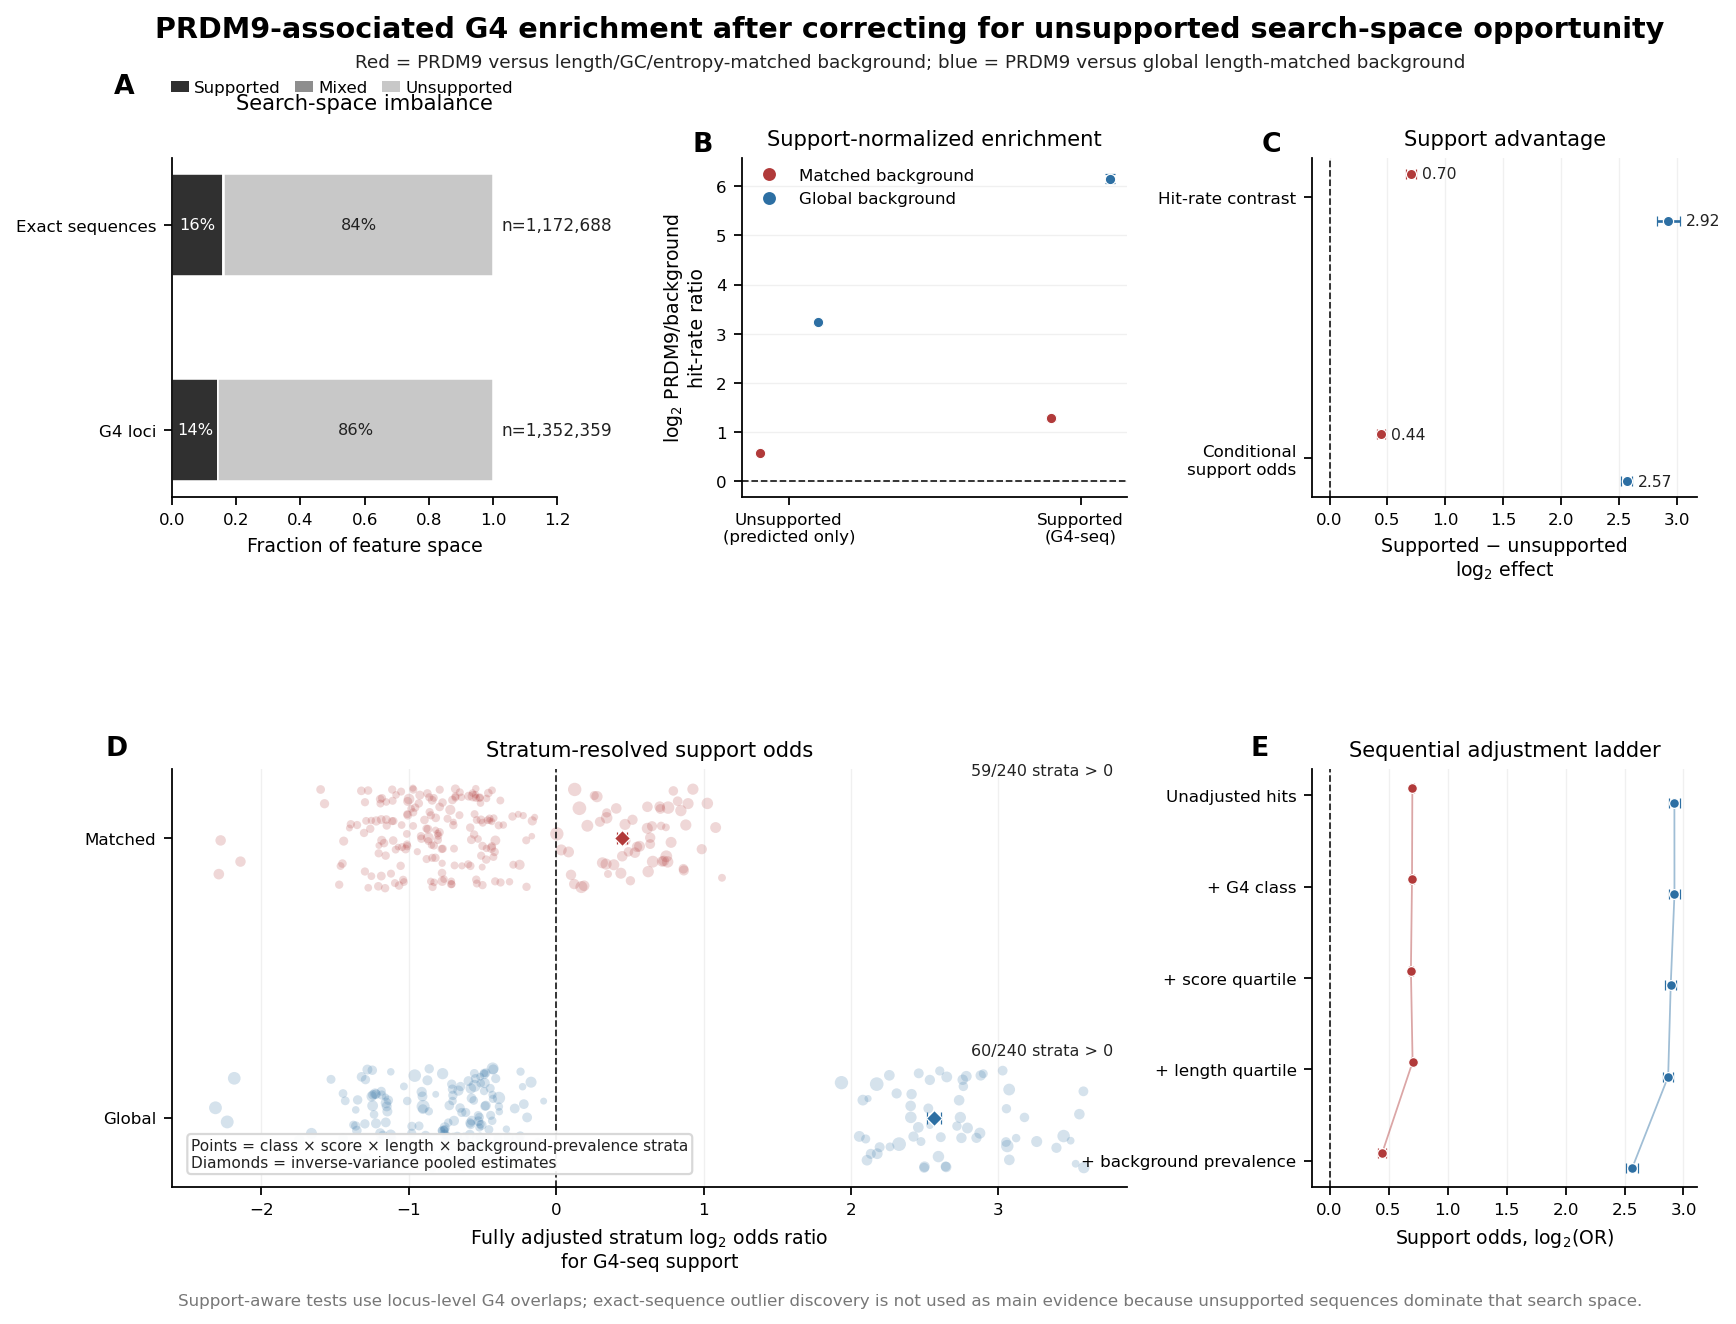

INFO | Main figure written: data_prdm9_g4seq_support_normalized_publication_v2/figures/Figure_PRDM9_G4seq_support_normalized_enrichment.png
INFO | Main figure written: data_prdm9_g4seq_support_normalized_publication_v2/figures/Figure_PRDM9_G4seq_support_normalized_enrichment.pdf
INFO | Main figure written: data_prdm9_g4seq_support_normalized_publication_v2/figures/Figure_PRDM9_G4seq_support_normalized_enrichment.svg


In [10]:

logger.info("[7/7] Building one publication-ready figure")

background_color = {"datasetA_matched": MATCHED_COLOR, "datasetB_global": GLOBAL_COLOR}
background_short = {"datasetA_matched": "Matched", "datasetB_global": "Global"}
background_label_order = ["datasetA_matched", "datasetB_global"]

composition = pd.DataFrame({
    "feature_space": ["G4 loci", "G4 loci", "Exact sequences", "Exact sequences", "Exact sequences"],
    "support_group": ["Supported", "Unsupported", "Supported", "Mixed", "Unsupported"],
    "n": [
        int(g4["Supported"].sum()),
        int((~g4["Supported"]).sum()),
        int((seq_catalog["support_display"] == "Supported").sum()),
        int((seq_catalog["support_display"] == "Mixed").sum()),
        int((seq_catalog["support_display"] == "Unsupported").sum()),
    ],
})


def fmt_p(p: float) -> str:
    if not np.isfinite(p):
        return "n/a"
    if p == 0 or p < 1e-300:
        return "<1e−300"
    if p < 1e-3:
        return f"{p:.1e}"
    return f"{p:.3f}"


def plot_composition(ax):
    order = ["G4 loci", "Exact sequences"]
    colors = {"Supported": SUPPORTED_COLOR, "Mixed": MIXED_COLOR, "Unsupported": UNSUPPORTED_COLOR}
    y_positions = np.arange(len(order))
    for yi, space in zip(y_positions, order):
        sub = composition[composition["feature_space"] == space]
        total = float(sub["n"].sum())
        left = 0.0
        for group in ["Supported", "Mixed", "Unsupported"]:
            n = float(sub.loc[sub["support_group"] == group, "n"].sum())
            frac = n / total if total else 0.0
            ax.barh(yi, frac, left=left, height=0.50, color=colors[group], edgecolor="white", linewidth=0.7)
            if frac > 0.075:
                ax.text(left + frac / 2, yi, f"{frac*100:.0f}%", ha="center", va="center", fontsize=7.3,
                        color="white" if group != "Unsupported" else DARK)
            left += frac
        ax.text(1.025, yi, f"n={int(total):,}", va="center", ha="left", fontsize=7.6, color=DARK)
    ax.set_xlim(0, 1.20)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(order)
    ax.set_xlabel("Fraction of feature space")
    ax.set_title("Search-space imbalance", pad=22)
    # Fixed: the legend is outside and above panel A, not inside the plotting region.
    ax.legend(
        handles=[Patch(facecolor=colors[g], label=g) for g in ["Supported", "Mixed", "Unsupported"]],
        frameon=False, loc="upper left", bbox_to_anchor=(-0.02, 1.25), ncol=3,
        borderaxespad=0.0, columnspacing=0.85, handlelength=1.05, handletextpad=0.35,
    )
    despine(ax)


def plot_support_rates(ax):
    x_base = {"Unsupported": 0, "Supported": 1}
    offsets = {"datasetA_matched": -0.10, "datasetB_global": 0.10}
    for bg_name in background_label_order:
        sub = support_rate[support_rate["background_name"] == bg_name]
        for _, row in sub.iterrows():
            x = x_base[row["support_group"]] + offsets[bg_name]
            color = background_color[bg_name]
            ax.errorbar(
                x, row["log2_rate_ratio"],
                yerr=[[row["log2_rate_ratio"] - row["ci_low"]], [row["ci_high"] - row["log2_rate_ratio"]]],
                fmt="o", color=color, ecolor=color, elinewidth=1.15, capsize=2.4,
                markersize=4.7, markeredgecolor="white", markeredgewidth=0.55, zorder=5,
            )
    ax.axhline(0, color=DARK, lw=0.8, ls="--")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Unsupported\n(predicted only)", "Supported\n(G4-seq)"])
    ax.set_ylabel("log$_2$ PRDM9/background\nhit-rate ratio")
    ax.set_title("Support-normalized enrichment")
    ax.grid(axis="y", alpha=0.18, lw=0.6)
    ax.legend(
        handles=[
            plt.Line2D([0], [0], marker="o", color=MATCHED_COLOR, label="Matched background", lw=0, markersize=4.8),
            plt.Line2D([0], [0], marker="o", color=GLOBAL_COLOR, label="Global background", lw=0, markersize=4.8),
        ],
        frameon=False, loc="upper left", bbox_to_anchor=(0.01, 0.99), borderaxespad=0.0,
    )
    despine(ax)


def plot_support_summary(ax):
    metrics = [
        ("Hit-rate contrast", "did_log2rr_supported_minus_unsupported", "did_ci_low", "did_ci_high", "did_fdr_bootstrap"),
        ("Conditional\nsupport odds", "stratified_log2_or", "stratified_log2_or_ci_low", "stratified_log2_or_ci_high", "stratified_fdr"),
    ]
    y_base = np.arange(len(metrics))[::-1]
    offsets = {"datasetA_matched": 0.09, "datasetB_global": -0.09}
    for yi, (label, value_col, lo_col, hi_col, p_col) in zip(y_base, metrics):
        for bg_name in background_label_order:
            row = support_contrast[support_contrast["background_name"] == bg_name].iloc[0]
            x = float(row[value_col])
            lo = float(row[lo_col])
            hi = float(row[hi_col])
            y = yi + offsets[bg_name]
            color = background_color[bg_name]
            ax.errorbar(
                x, y, xerr=[[x - lo], [hi - x]], fmt="o", color=color, ecolor=color,
                elinewidth=1.2, capsize=2.4, markersize=4.6, markeredgecolor="white", markeredgewidth=0.55,
            )
            ax.text(hi + 0.05, y, f"{x:.2f}", va="center", ha="left", fontsize=7.0, color=DARK)
    ax.axvline(0, color=DARK, lw=0.8, ls="--")
    ax.set_yticks(y_base)
    ax.set_yticklabels([m[0] for m in metrics])
    ax.set_xlabel("Supported − unsupported\nlog$_2$ effect")
    ax.set_title("Support advantage")
    ax.grid(axis="x", alpha=0.18, lw=0.6)
    despine(ax)


def plot_stratum_resolved(ax):
    rng = np.random.default_rng(RANDOM_SEED)
    base_y = {"datasetA_matched": 1.0, "datasetB_global": 0.0}
    for bg_name in background_label_order:
        sub = strata_df[strata_df["background_name"] == bg_name].copy()
        if sub.empty:
            continue
        color = background_color[bg_name]
        # deterministic visual jitter; avoids overplotting but remains reproducible.
        jitter = rng.uniform(-0.18, 0.18, len(sub))
        sizes = 8 + 30 * np.sqrt(sub["total_hits"].to_numpy(np.float64) / max(float(sub["total_hits"].max()), 1.0))
        ax.scatter(
            sub["log2_or"], base_y[bg_name] + jitter,
            s=sizes, c=color, alpha=0.20, edgecolor="none", rasterized=True,
        )
        row = support_contrast[support_contrast["background_name"] == bg_name].iloc[0]
        x = row["stratified_log2_or"]
        lo = row["stratified_log2_or_ci_low"]
        hi = row["stratified_log2_or_ci_high"]
        ax.errorbar(
            x, base_y[bg_name], xerr=[[x - lo], [hi - x]], fmt="D", color=color, ecolor=color,
            elinewidth=1.35, capsize=2.6, markersize=5.2, markeredgecolor="white", markeredgewidth=0.55,
            zorder=6,
        )
        n_pos = int((sub["log2_or"] > 0).sum())
        ax.text(0.985, base_y[bg_name] + 0.24, f"{n_pos}/{len(sub)} strata > 0", transform=ax.get_yaxis_transform(),
                ha="right", va="center", fontsize=7.2, color=DARK)
    ax.axvline(0, color=DARK, lw=0.8, ls="--")
    ax.set_yticks([1, 0])
    ax.set_yticklabels(["Matched", "Global"])
    ax.set_xlabel("Fully adjusted stratum log$_2$ odds ratio\nfor G4-seq support")
    ax.set_title("Stratum-resolved support odds")
    ax.grid(axis="x", alpha=0.18, lw=0.6)
    ax.text(0.02, 0.04, "Points = class × score × length × background-prevalence strata\nDiamonds = inverse-variance pooled estimates",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=6.9, color=DARK,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=LIGHT, alpha=0.94))
    despine(ax)


def plot_ladder(ax):
    model_order = [m[0] for m in MODEL_LADDER]
    y_positions = np.arange(len(model_order))
    offsets = {"datasetA_matched": -0.08, "datasetB_global": 0.08}
    for bg_name in background_label_order:
        sub = ladder_df[ladder_df["background_name"] == bg_name].set_index("model_label").loc[model_order].reset_index()
        color = background_color[bg_name]
        for yi, (_, row) in zip(y_positions, sub.iterrows()):
            x = float(row["stratified_log2_or"])
            lo = float(row["stratified_log2_or_ci_low"])
            hi = float(row["stratified_log2_or_ci_high"])
            ax.errorbar(
                x, yi + offsets[bg_name], xerr=[[x - lo], [hi - x]], fmt="o", color=color, ecolor=color,
                elinewidth=1.1, capsize=2.2, markersize=4.4, markeredgecolor="white", markeredgewidth=0.55,
            )
        ax.plot(sub["stratified_log2_or"], y_positions + offsets[bg_name], color=color, lw=0.8, alpha=0.45)
    ax.axvline(0, color=DARK, lw=0.8, ls="--")
    ax.set_yticks(y_positions)
    ax.set_yticklabels(model_order)
    ax.invert_yaxis()
    ax.set_xlabel("Support odds, log$_2$(OR)")
    ax.set_title("Sequential adjustment ladder")
    ax.grid(axis="x", alpha=0.18, lw=0.6)
    despine(ax)


fig = plt.figure(figsize=(12.3, 8.35), constrained_layout=False)
gs = fig.add_gridspec(2, 3, height_ratios=[0.94, 1.16], hspace=0.72, wspace=0.48)
axA = fig.add_subplot(gs[0, 0])
axB = fig.add_subplot(gs[0, 1])
axC = fig.add_subplot(gs[0, 2])
axD = fig.add_subplot(gs[1, 0:2])
axE = fig.add_subplot(gs[1, 2])

plot_composition(axA)
plot_support_rates(axB)
plot_support_summary(axC)
plot_stratum_resolved(axD)
plot_ladder(axE)

add_panel_label(axA, "A", x=-0.15, y=1.25)
add_panel_label(axB, "B", x=-0.13, y=1.08)
add_panel_label(axC, "C", x=-0.13, y=1.08)
add_panel_label(axD, "D", x=-0.07, y=1.08)
add_panel_label(axE, "E", x=-0.16, y=1.08)

fig.suptitle("PRDM9-associated G4 enrichment after correcting for unsupported search-space opportunity",
             fontsize=12.9, fontweight="bold", y=0.987)
fig.text(0.5, 0.952,
         "Red = PRDM9 versus length/GC/entropy-matched background; blue = PRDM9 versus global length-matched background",
         ha="center", va="center", fontsize=8.3, color=DARK)
fig.text(0.5, 0.025,
         "Support-aware tests use locus-level G4 overlaps; exact-sequence outlier discovery is not used as main evidence because unsupported sequences dominate that search space.",
         ha="center", va="center", fontsize=7.5, color=MID)

fig.tight_layout(rect=[0.025, 0.055, 0.995, 0.91])
fig.savefig(FIG_MAIN_PNG, bbox_inches="tight", facecolor="white")
fig.savefig(FIG_MAIN_PDF, bbox_inches="tight", facecolor="white")
fig.savefig(FIG_MAIN_SVG, bbox_inches="tight", facecolor="white")
plt.show()

logger.info(f"Main figure written: {FIG_MAIN_PNG}")
logger.info(f"Main figure written: {FIG_MAIN_PDF}")
logger.info(f"Main figure written: {FIG_MAIN_SVG}")



## 8. Metadata and run summary

The printed summary tables are the values that directly support the main figure.



INFO | [7/7] Building simplified publication-ready support figure


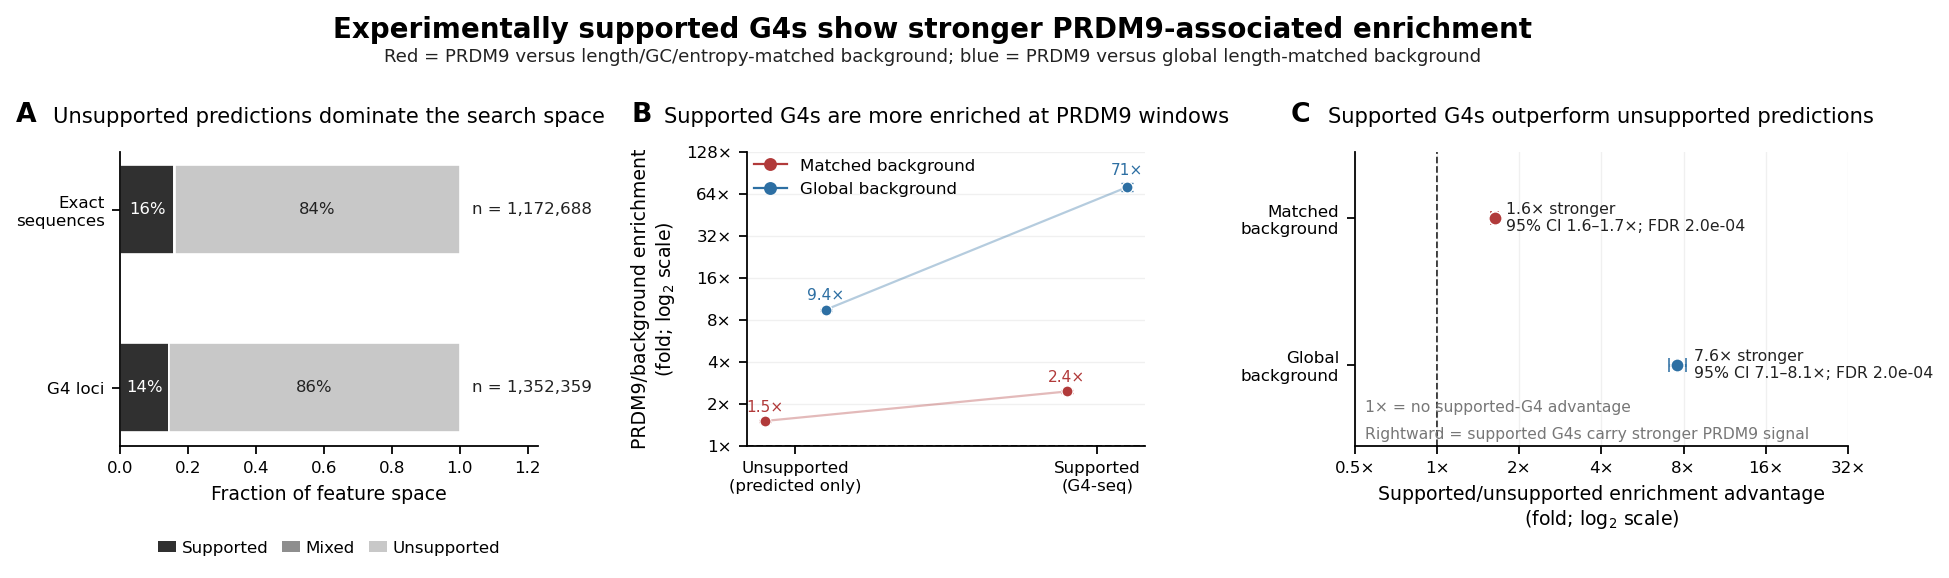

INFO | Main simplified figure written: data_prdm9_g4seq_support_normalized_publication_v2/figures/Figure_PRDM9_G4seq_support_normalized_enrichment_ABC.png
INFO | Main simplified figure written: data_prdm9_g4seq_support_normalized_publication_v2/figures/Figure_PRDM9_G4seq_support_normalized_enrichment_ABC.pdf
INFO | Main simplified figure written: data_prdm9_g4seq_support_normalized_publication_v2/figures/Figure_PRDM9_G4seq_support_normalized_enrichment_ABC.svg


In [27]:
# ---------------------------------------------------------------------
# Step 7/7: publication-ready support figure (simplified A–C version)
# ---------------------------------------------------------------------
# This replaces the whole previous Step 7 cell.
# It deliberately drops the stratum-resolved and sequential-ladder panels,
# because they are statistically useful diagnostics but visually dilute the
# core message. The final figure now tells one story:
#   A) unsupported predictions dominate the search space,
#   B) supported G4s are more enriched at PRDM9 windows after normalization,
#   C) the supported-vs-unsupported advantage as an intuitive fold effect.

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

try:
    logger.info("[7/7] Building simplified publication-ready support figure")
except Exception:
    print("[7/7] Building simplified publication-ready support figure")

# ---------------------------------------------------------------------
# Local plotting helpers
# ---------------------------------------------------------------------
background_color = {"datasetA_matched": MATCHED_COLOR, "datasetB_global": GLOBAL_COLOR}
background_label = {"datasetA_matched": "Matched background", "datasetB_global": "Global background"}
background_short = {"datasetA_matched": "Matched", "datasetB_global": "Global"}
background_order = ["datasetA_matched", "datasetB_global"]

support_colors = {
    "Supported": SUPPORTED_COLOR,
    "Mixed": MIXED_COLOR,
    "Unsupported": UNSUPPORTED_COLOR,
}


def _despine(ax):
    """Use notebook despine() if present; otherwise fall back to a small local version."""
    if "despine" in globals():
        despine(ax)
    else:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)


def _panel_label(ax, label, x=-0.12, y=1.06):
    """Use notebook add_panel_label() if present; otherwise fall back to local text."""
    if "add_panel_label" in globals():
        add_panel_label(ax, label, x=x, y=y)
    else:
        ax.text(x, y, label, transform=ax.transAxes, fontsize=13, fontweight="bold", va="top", ha="left")


def _fmt_p(p: float) -> str:
    if not np.isfinite(p):
        return "n/a"
    if p == 0 or p < 1e-300:
        return "<1e−300"
    if p < 1e-3:
        return f"{p:.1e}"
    return f"{p:.3f}"


def _fold_from_log2(x: float) -> float:
    return float(2.0 ** float(x))


def _fold_tick_label(log2_value: float) -> str:
    fold = _fold_from_log2(log2_value)
    if fold < 1:
        return f"{fold:.2g}×"
    if fold < 10:
        return f"{fold:.1f}×" if not np.isclose(fold, round(fold)) else f"{fold:.0f}×"
    return f"{fold:.0f}×"


def _safe_row(df: pd.DataFrame, background_name: str, support_group: str | None = None) -> pd.Series:
    sub = df[df["background_name"] == background_name]
    if support_group is not None:
        sub = sub[sub["support_group"] == support_group]
    if sub.empty:
        raise RuntimeError(f"Missing row for background={background_name!r}, support_group={support_group!r}")
    return sub.iloc[0]


# ---------------------------------------------------------------------
# Panel A data: how imbalanced is the search space?
# ---------------------------------------------------------------------
seq_support_counts = seq_catalog["support_display"].value_counts().to_dict()
composition = pd.DataFrame({
    "feature_space": ["G4 loci", "G4 loci", "Exact sequences", "Exact sequences", "Exact sequences"],
    "support_group": ["Supported", "Unsupported", "Supported", "Mixed", "Unsupported"],
    "n": [
        int(g4["Supported"].fillna(False).astype(bool).sum()),
        int((~g4["Supported"].fillna(False).astype(bool)).sum()),
        int(seq_support_counts.get("Supported", 0)),
        int(seq_support_counts.get("Mixed", 0)),
        int(seq_support_counts.get("Unsupported", 0)),
    ],
})


# ---------------------------------------------------------------------
# Panel A: search-space imbalance
# ---------------------------------------------------------------------
def plot_search_space_imbalance(ax):
    order = ["G4 loci", "Exact sequences"]
    y_positions = np.arange(len(order))

    for yi, space in zip(y_positions, order):
        sub = composition[composition["feature_space"] == space]
        total = float(sub["n"].sum())
        left = 0.0

        for group in ["Supported", "Mixed", "Unsupported"]:
            n = float(sub.loc[sub["support_group"] == group, "n"].sum())
            frac = n / total if total else 0.0
            ax.barh(
                yi, frac, left=left, height=0.50,
                color=support_colors[group], edgecolor="white", linewidth=0.75,
            )
            if frac >= 0.075:
                txt_color = "white" if group in {"Supported", "Mixed"} else DARK
                ax.text(left + frac / 2, yi, f"{frac * 100:.0f}%", ha="center", va="center",
                        fontsize=7.4, color=txt_color)
            elif frac >= 0.018:
                # Small but visible segments get an outside label instead of a hidden/overlapping one.
                ax.text(left + frac + 0.012, yi + 0.20, f"{frac * 100:.1f}%", ha="left", va="center",
                        fontsize=6.8, color=DARK)
            left += frac

        ax.text(1.035, yi, f"n = {int(total):,}", va="center", ha="left", fontsize=7.5, color=DARK)

    ax.set_xlim(0, 1.23)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(["G4 loci", "Exact\nsequences"])
    ax.set_xlabel("Fraction of feature space")
    ax.set_title("Unsupported predictions dominate the search space", pad=13)

    # Important fix: legend is below panel A, outside the data region and away from the figure title/subtitle.
    ax.legend(
        handles=[Patch(facecolor=support_colors[g], label=g) for g in ["Supported", "Mixed", "Unsupported"]],
        frameon=False, loc="upper center", bbox_to_anchor=(0.50, -0.30), ncol=3,
        borderaxespad=0.0, columnspacing=0.85, handlelength=1.05, handletextpad=0.35,
    )
    _despine(ax)


# ---------------------------------------------------------------------
# Panel B: support-normalized enrichment
# ---------------------------------------------------------------------
def plot_support_normalized_enrichment(ax):
    x_base = {"Unsupported": 0.0, "Supported": 1.0}
    offsets = {"datasetA_matched": -0.10, "datasetB_global": 0.10}

    # Draw connecting lines first: same background comparison, unsupported -> supported.
    for bg_name in background_order:
        xs, ys = [], []
        for support_group in ["Unsupported", "Supported"]:
            row = _safe_row(support_rate, bg_name, support_group)
            xs.append(x_base[support_group] + offsets[bg_name])
            ys.append(float(row["log2_rate_ratio"]))
        ax.plot(xs, ys, color=background_color[bg_name], lw=1.0, alpha=0.35, zorder=2)

    # Draw CIs and point estimates.
    for bg_name in background_order:
        for support_group in ["Unsupported", "Supported"]:
            row = _safe_row(support_rate, bg_name, support_group)
            x = x_base[support_group] + offsets[bg_name]
            y = float(row["log2_rate_ratio"])
            lo = float(row["ci_low"])
            hi = float(row["ci_high"])
            color = background_color[bg_name]
            ax.errorbar(
                x, y, yerr=[[y - lo], [hi - y]],
                fmt="o", color=color, ecolor=color, elinewidth=1.15, capsize=2.5,
                markersize=5.0, markeredgecolor="white", markeredgewidth=0.60, zorder=5,
            )
            ax.text(x, hi + 0.13, _fold_tick_label(y), ha="center", va="bottom", fontsize=6.9, color=color)

    y_min = min(0.0, float(support_rate["ci_low"].min()) - 0.35)
    y_max = float(support_rate["ci_high"].max()) + 0.70
    y_min_tick = math.floor(y_min)
    y_max_tick = math.ceil(y_max)
    yticks = np.arange(y_min_tick, y_max_tick + 1, 1)

    ax.axhline(0, color=DARK, lw=0.8, ls="--", zorder=1)
    ax.set_ylim(y_min, y_max)
    ax.set_yticks(yticks)
    ax.set_yticklabels([_fold_tick_label(t) for t in yticks])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Unsupported\n(predicted only)", "Supported\n(G4-seq)"])
    ax.set_ylabel("PRDM9/background enrichment\n(fold; log$_2$ scale)")
    ax.set_title("Supported G4s are more enriched at PRDM9 windows", pad=13)
    ax.grid(axis="y", alpha=0.18, lw=0.6)

    ax.legend(
        handles=[
            Line2D([0], [0], marker="o", color=background_color["datasetA_matched"], label="Matched background", lw=1.0, markersize=4.8),
            Line2D([0], [0], marker="o", color=background_color["datasetB_global"], label="Global background", lw=1.0, markersize=4.8),
        ],
        frameon=False, loc="upper left", bbox_to_anchor=(0.00, 1.00), borderaxespad=0.0,
    )
    _despine(ax)


# ---------------------------------------------------------------------
# Panel C: direct supported-vs-unsupported advantage
# ---------------------------------------------------------------------
def plot_supported_advantage(ax):
    # This is intentionally just the rate-based difference-in-differences from panel B:
    #   log2( supported PRDM9/background ) - log2( unsupported PRDM9/background )
    # Plotted as a fold advantage so readers do not need to mentally decode log2 units.
    y_pos = {"datasetA_matched": 1.0, "datasetB_global": 0.0}

    for bg_name in background_order:
        row = support_contrast[support_contrast["background_name"] == bg_name]
        if row.empty:
            raise RuntimeError(f"Missing support_contrast row for {bg_name}")
        row = row.iloc[0]

        x = float(row["did_log2rr_supported_minus_unsupported"])
        lo = float(row["did_ci_low"])
        hi = float(row["did_ci_high"])
        y = y_pos[bg_name]
        color = background_color[bg_name]
        fold = _fold_from_log2(x)
        lo_fold = _fold_from_log2(lo)
        hi_fold = _fold_from_log2(hi)

        ax.errorbar(
            x, y, xerr=[[x - lo], [hi - x]],
            fmt="o", color=color, ecolor=color, elinewidth=1.35, capsize=3.0,
            markersize=6.0, markeredgecolor="white", markeredgewidth=0.70, zorder=5,
        )

        p_col = "did_fdr_bootstrap" if "did_fdr_bootstrap" in row.index else "did_p_bootstrap"
        p_txt = _fmt_p(float(row[p_col]))
        ax.text(
            hi + 0.10, y,
            f"{fold:.1f}× stronger\n95% CI {lo_fold:.1f}–{hi_fold:.1f}×; FDR {p_txt}",
            ha="left", va="center", fontsize=7.1, color=DARK,
        )

    max_hi = float(support_contrast["did_ci_high"].max())
    min_lo = float(support_contrast["did_ci_low"].min())
    x_min = min(-0.25, min_lo - 0.20)
    x_max = max(1.30, max_hi + 1.15)
    left_tick = math.floor(x_min)
    right_tick = math.ceil(x_max)
    xticks = np.arange(left_tick, right_tick + 1, 1)

    ax.axvline(0, color=DARK, lw=0.8, ls="--", zorder=1)
    ax.text(0.02, 0.13, "1× = no supported-G4 advantage", transform=ax.transAxes,
            ha="left", va="center", fontsize=7.0, color=MID)
    ax.text(0.02, 0.04, "Rightward = supported G4s carry stronger PRDM9 signal", transform=ax.transAxes,
            ha="left", va="center", fontsize=7.0, color=MID)

    ax.set_xlim(x_min, x_max)
    ax.set_xticks(xticks)
    ax.set_xticklabels([_fold_tick_label(t) for t in xticks])
    ax.set_ylim(-0.55, 1.45)
    ax.set_yticks([1, 0])
    ax.set_yticklabels(["Matched\nbackground", "Global\nbackground"])
    ax.set_xlabel("Supported/unsupported enrichment advantage\n(fold; log$_2$ scale)")
    ax.set_title("Supported G4s outperform unsupported predictions", pad=13)
    ax.grid(axis="x", alpha=0.18, lw=0.6)
    _despine(ax)


# ---------------------------------------------------------------------
# Build and save the final simplified figure
# ---------------------------------------------------------------------
FIG_ABC_PNG = FIG_DIR / "Figure_PRDM9_G4seq_support_normalized_enrichment_ABC.png"
FIG_ABC_PDF = FIG_DIR / "Figure_PRDM9_G4seq_support_normalized_enrichment_ABC.pdf"
FIG_ABC_SVG = FIG_DIR / "Figure_PRDM9_G4seq_support_normalized_enrichment_ABC.svg"

fig = plt.figure(figsize=(11.8, 3.95), constrained_layout=False)
gs = fig.add_gridspec(1, 3, width_ratios=[1.10, 1.05, 1.30], wspace=0.48)

axA = fig.add_subplot(gs[0, 0])
axB = fig.add_subplot(gs[0, 1])
axC = fig.add_subplot(gs[0, 2])

plot_search_space_imbalance(axA)
plot_support_normalized_enrichment(axB)
plot_supported_advantage(axC)

# Panel letters: placed outside axes so they do not collide with subplot titles.
_panel_label(axA, "A", x=-0.25, y=1.17)
_panel_label(axB, "B", x=-0.29, y=1.17)
_panel_label(axC, "C", x=-0.13, y=1.17)

fig.suptitle(
    "Experimentally supported G4s show stronger PRDM9-associated enrichment",
    fontsize=12.5, fontweight="bold", y=0.965,
)
fig.text(
    0.5, 0.900,
    "Red = PRDM9 versus length/GC/entropy-matched background; blue = PRDM9 versus global length-matched background",
    ha="center", va="center", fontsize=8.2, color=DARK,
)

fig.subplots_adjust(left=0.070, right=0.985, top=0.750, bottom=0.285, wspace=0.7)

# Save both under new explicit A–C names and the notebook's standard FIG_MAIN_* names.
for path in [FIG_ABC_PNG, FIG_MAIN_PNG]:
    fig.savefig(path, bbox_inches="tight", facecolor="white")
for path in [FIG_ABC_PDF, FIG_MAIN_PDF]:
    fig.savefig(path, bbox_inches="tight", facecolor="white")
for path in [FIG_ABC_SVG, FIG_MAIN_SVG]:
    fig.savefig(path, bbox_inches="tight", facecolor="white")

plt.show()

try:
    logger.info(f"Main simplified figure written: {FIG_ABC_PNG}")
    logger.info(f"Main simplified figure written: {FIG_ABC_PDF}")
    logger.info(f"Main simplified figure written: {FIG_ABC_SVG}")
except Exception:
    print(f"Main simplified figure written: {FIG_ABC_PNG}")
    print(f"Main simplified figure written: {FIG_ABC_PDF}")
    print(f"Main simplified figure written: {FIG_ABC_SVG}")